# Calibrating Fisher forecasts of the core size against inference

How well does a Fisher forecast predict the uncertainty on the CIS core size $x_c$ that full Bayesian inference finds? This notebook compares the two for the LIGO mass scan of the paper: a lens with $x_c = 0.02$ at $y = 0.3$, for $M_{Lz} = 3$ to $1000\,M_\odot$, with the 30+30 $M_\odot$ benchmark source at 500 Mpc.

1. Read the width of the $x_c$ posterior from the shipped mass-scan samples.
2. Read the Fisher covariance of $(\ln M_{Lz}, y, x_c)$ at the same points, and restrict the Fisher Gaussian to the prior used in inference.
3. Compare the two (the paper's calibration figure).
4. Translate the same posteriors into the SIDM cross section, marginalizing over the lens redshift as in Tambalo et al. (2023, T23), and show how the bound tightens with lens mass.
5. Compare these limits with other probes of SIDM (the paper's two SIDM figures).
6. Read the same core limits as lower limits on the ultralight-axion mass, as in T23.
7. Compare them with the most competitive ultralight-axion bounds.
8. Place the PBH masses measured along the PBH mass scan on the standard plot of PBH bounds.

The Fisher grid ships in `data/core_fisher_LIGO_CIS.npz`. To recompute it, run `python scripts/1_fisher/core_size_fisher.py LIGO` (about 15 minutes on 112 cores, `slurm/core_size_fisher.sh`).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from infer_with_fiona import paths, posteriors

## 1. Posterior width of $x_c$

The mass-scan runs sample $x_c$ (stored as `lp`) with a flat prior on $[0, 1]$. Where the data carry no information on the core, the posterior width approaches the width of that prior, $1/\sqrt{12} \approx 0.29$.

In [2]:
MASSES = [3, 10, 30, 100, 300, 1000]
XC_TRUE, Y_TRUE = 0.02, 0.3
pe_std = {m: posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))[0]['lp'].std() for m in MASSES}
pd.Series(pe_std, name='posterior std of x_c').rename_axis('M_Lz').to_frame().T

M_Lz,3,10,30,100,300,1000
posterior std of x_c,0.287802,0.277873,0.200071,0.125345,0.031577,0.011368


## 2. The Fisher forecast, restricted to the prior

The Fisher grid holds, at each $(x_c, M_{Lz}, y)$, the covariance of $(\ln M_{Lz}, y, x_c)$ after marginalizing over the distance, the phase and the arrival time, as in inference. Where the data are weak this Gaussian is much wider than the prior, and part of it lies at unphysical values such as $x_c < 0$. Comparing its raw $\sigma(x_c)$ with the posterior would count that region.

The inference prior is flat in $(\ln M_{Lz}, y, x_c)$: log-uniform $M_{Lz} \in [0.1, 2000]\,M_\odot$, $y \in [0.1, 5]$, $x_c \in [0, 1]$. So the Fisher approximation of the posterior is the Fisher Gaussian truncated to that box. We draw from the Gaussian, keep the draws inside the box, and take the standard deviation of $x_c$. (The prior also excludes a narrow band around the caustic, which we do not remove here.)

In [3]:
grid = np.load(paths.CORE_FISHER_GRID)
LNM_BOX, Y_BOX, XC_BOX = (np.log(0.1), np.log(2000.0)), (0.1, 5.0), (0.0, 1.0)
Z = np.random.default_rng(1).standard_normal((400000, 3))      # the same normal draws for every point


def truncated_std(cov, truth):
    # std of x_c for the Gaussian N(truth, cov) in (ln M_Lz, y, x_c), restricted to the prior box
    w, V = np.linalg.eigh(cov)
    s = np.asarray(truth) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
    inside = ((s[:, 0] >= LNM_BOX[0]) & (s[:, 0] <= LNM_BOX[1]) & (s[:, 1] >= Y_BOX[0]) & (s[:, 1] <= Y_BOX[1])
              & (s[:, 2] >= XC_BOX[0]) & (s[:, 2] <= XC_BOX[1]))
    return s[inside, 2].std()


i, k = list(grid['x_c']).index(XC_TRUE), list(grid['y']).index(Y_TRUE)
M_grid = grid['M_Lz']
raw = grid['sigma_xc_t'][i, :, k]                                        # with t_c, as in inference
trunc = np.array([truncated_std(grid['cov_t'][i, j, k], (np.log(M), Y_TRUE, XC_TRUE)) for j, M in enumerate(M_grid)])

# the PE masses fall between grid masses: interpolate in log M_Lz
interp = lambda v, m: 10 ** np.interp(np.log10(m), np.log10(M_grid), np.log10(v))
CAL = pd.DataFrame({'M_Lz': MASSES, 'posterior std': [pe_std[m] for m in MASSES],
                    'Fisher sigma (no prior)': [interp(raw, m) for m in MASSES],
                    'Fisher std (truncated to prior)': [interp(trunc, m) for m in MASSES]})
CAL['posterior / Fisher (truncated)'] = CAL['posterior std'] / CAL['Fisher std (truncated to prior)']
CAL.round(3)

,M_Lz,posterior std,Fisher sigma (no prior),Fisher std (truncated to prior),posterior / Fisher (truncated)
0,3,0.288,24.091,0.296,0.972
1,10,0.278,5.842,0.287,0.967
2,30,0.200,1.566,0.269,0.745
3,100,0.125,0.473,0.159,0.788
4,300,0.032,0.131,0.072,0.441
5,1000,0.011,0.014,0.012,0.934


Without the prior, the Fisher $\sigma(x_c)$ exceeds the width of the prior by up to two orders of magnitude at low lens mass, where it only says that the data carry no information. Truncated to the prior, it reproduces the posterior there. At $M_{Lz} = 1000\,M_\odot$, where the data dominate, the two methods agree to 10%. In between ($M_{Lz} = 30$ to $300\,M_\odot$) the Fisher forecast is conservative by a factor of up to about two, because the likelihood there is far from Gaussian.

## 3. The calibration figure

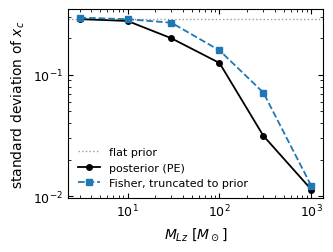

In [4]:
paths.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 8, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    ax.axhline(1 / np.sqrt(12), color='0.6', ls=':', lw=1, label='flat prior')
    ax.loglog(CAL['M_Lz'], CAL['posterior std'], 'o-', color='k', ms=4, lw=1.3, label='posterior (PE)')
    ax.loglog(CAL['M_Lz'], CAL['Fisher std (truncated to prior)'], 's--', color='tab:blue', ms=4, lw=1.3,
              label='Fisher, truncated to prior')
    ax.set(xlabel=r'$M_{Lz}\ [M_\odot]$', ylabel=r'standard deviation of $x_c$')
    ax.legend(frameon=False, loc='lower left')
    fig.tight_layout()
    for ext in ('pdf', 'png'):
        fig.savefig(paths.FIGURES_DIR / f'calibration_width.{ext}', dpi=300, bbox_inches='tight')
    plt.show()

## 4. SIDM cross section along the mass scan

Reading the CIS core as an SIDM core, the core-formation condition $\langle\sigma v\rangle\,\rho(r_c)\,t_{\rm age}/m \simeq 1$ on the CIS profile gives the cross section per unit mass,
$$\frac{\sigma}{m} = \frac{4\pi G\,(x_c\,\xi_0)^2}{\sigma_v^2\,\langle v\rangle\,t_{\rm age}},\qquad \sigma_v^2 = \frac{\xi_0\,c^2}{4\pi D},\qquad \langle v\rangle = \frac{4\sigma_v}{\sqrt{\pi}},$$
where $\xi_0$ is the Einstein radius, $D = D_L D_{LS}/D_S$, and $t_{\rm age} = 5$ Gyr.

The conversion needs the lens redshift, which a single event does not measure. As in T23 (their Eq. 69), we marginalize over it with
$$\frac{dP}{dz_L} \propto \xi_0^2\,\frac{(1+z_L)^2}{H(z_L)}\left|\frac{\partial M_{Lz}}{\partial M_{\rm vir}}\right|^{-1}\frac{dn}{dM_{\rm vir}}\bigl(M_{\rm vir}(M_{Lz}, z_L), z_L\bigr),$$
the lensing cross section times the comoving volume and the number density of halos of the mass that gives the measured $M_{Lz}$ at that redshift. $M_{\rm vir}(M_{Lz}, z_L)$ is T23's SIS relation and $dn/dM_{\rm vir}$ the Tinker et al. (2008) mass function from Colossus, in the flat cosmology used throughout ($H_0 = 70$ km/s/Mpc, $\Omega_m = 0.3$).

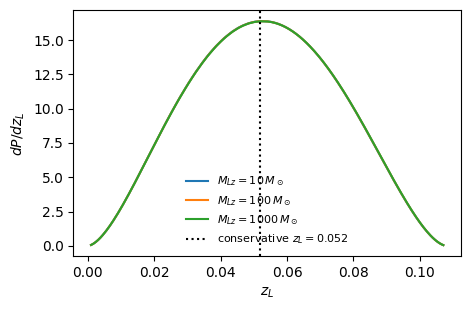

In [5]:
from colossus.cosmology import cosmology
from colossus.lss import mass_function
from scipy.constants import G as G_SI, c as C_SI
from infer_with_fiona import dm_conversions as D

MSUN, GPC_M, GYR_S = 1.98847e30, 3.0856775814913673e25, 3.15576e16
H0, OM = 70.0, 0.3
cosmo = cosmology.setCosmology('paper_flat70', {'flat': True, 'H0': H0, 'Om0': OM, 'Ob0': 0.0486,
                                                'sigma8': 0.8159, 'ns': 0.9667})
z_S = D.z_source(500.0)                                   # the injected source, d_L = 500 Mpc
z_L_cons = D.zL_pessimistic(z_S)                          # T23's conservative choice, for reference


def m_vir(mlz, zl, deff):
    # T23's SIS relation between the lens mass and the virial mass (their Eq. A11, h = 0.7)
    return (mlz * (6.5e17 * deff ** -3) ** (1 / 3) / (2 * (1 + zl) ** 2)) ** 0.75


class LensRedshift:
    # T23's lens-redshift distribution (their Eq. 69) for a source at z_s, tabulated against M_Lz

    def __init__(self, z_s, logm_min, logm_max, n_m=70, n_z=300):
        self.zs = z_s
        self.z = np.linspace(1e-3, z_s - 1e-3, n_z)
        self.deff = np.array([D.d_eff_Gpc(float(z), z_s) for z in self.z])    # d_eff(z_L) [Gpc]
        self.logm = np.linspace(logm_min, logm_max, n_m)
        cdf = []
        for lm in self.logm:
            p = self.pdf(10 ** lm)
            c = np.concatenate([[0], np.cumsum(0.5 * (p[1:] + p[:-1]) * np.diff(self.z))])
            cdf.append(c / c[-1])
        self.cdf = np.array(cdf)

    def pdf(self, mlz):
        mv = m_vir(mlz, self.z, self.deff)
        dndlnM = np.array([mass_function.massFunction(m * cosmo.h, z, mdef='200c', model='tinker08', q_out='dndlnM')
                           for m, z in zip(mv, self.z)])
        xi0_sq = 4 * G_SI * mlz * MSUN * self.deff * GPC_M / C_SI ** 2
        Hz = np.sqrt(OM * (1 + self.z) ** 3 + 1 - OM)
        p = xi0_sq * (1 + self.z) ** 2 / Hz * 0.75 * mv / mlz * dndlnM * cosmo.h ** 3 / mv
        return p / np.trapezoid(p, self.z)

    def draw(self, mlz):
        # one z_L per sample, from P(z_L | M_Lz) at the nearest tabulated mass
        mlz = np.atleast_1d(mlz)
        i = np.clip(np.round(np.interp(np.log10(mlz), self.logm, np.arange(len(self.logm)))).astype(int),
                    0, len(self.logm) - 1)
        return np.array([np.interp(u, self.cdf[ii], self.z) for u, ii in zip(rng.uniform(size=len(mlz)), i)])

    def v_and_sigma_over_m(self, xc, mlz, zl, t_age_gyr=5.0):
        # <v> [km/s] and sigma/m [cm^2/g] from the core-formation condition on the CIS profile
        deff = np.interp(zl, self.z, self.deff) * GPC_M
        xi0 = np.sqrt(4 * G_SI * mlz * MSUN * deff / C_SI ** 2)
        sv = np.sqrt(xi0 * C_SI ** 2 / (4 * np.pi * (1 + zl) * deff))
        v = 4 / np.sqrt(np.pi) * sv
        return v / 1e3, 4 * np.pi * G_SI * (np.asarray(xc) * xi0) ** 2 / (sv ** 2 * v * t_age_gyr * GYR_S) * 10.0


rng = np.random.default_rng(20261020)
ZLIGO = LensRedshift(z_S, -1.2, np.log10(2000) + 0.6)
ZL, draw_zL, v_and_sigma_over_m, p_zL = ZLIGO.z, ZLIGO.draw, ZLIGO.v_and_sigma_over_m, ZLIGO.pdf


fig, ax = plt.subplots(figsize=(5, 3.2))
for m in [10, 100, 1000]:
    ax.plot(ZL, p_zL(m), label=rf'$M_{{Lz}}={m}\,M_\odot$')
ax.axvline(z_L_cons, color='k', ls=':', label=f'conservative $z_L={z_L_cons:.3f}$')
ax.set(xlabel='$z_L$', ylabel=r'$dP/dz_L$')
ax.legend(fontsize=8, frameon=False)
plt.show()

For our nearby source ($z_S = 0.108$) and these light halos, the mass function hardly changes between $z_L = 0$ and $0.1$, so $P(z_L)$ follows the lensing cross section $\propto \xi_0^2 \propto d_{\rm eff}$. It is the same for every $M_{Lz}$ and peaks at T23's conservative choice, the $z_L$ that maximizes $(1+z_L)\,d_{\rm eff}$.

Each posterior sample of $(M_{Lz}, x_c)$ gets its own $z_L$ drawn from $P(z_L \mid M_{Lz})$. At $M_{Lz} = 3$ and $10\,M_\odot$ the $x_c$ posterior fills its prior, so only $M_{Lz} \ge 30\,M_\odot$ are shown. The injected value is shown at the median over $P(z_L)$.

In [6]:
SCAN = [30, 100, 300, 1000]
SIG, INJ, VEL = {}, {}, {}
rows = []
for m in SCAN:
    s, _ = posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))
    mlz = np.asarray(s['MLz'])
    SIG[m] = v_and_sigma_over_m(np.maximum(s['lp'], 1e-6), mlz, draw_zL(mlz))[1]
    v_t, s_t = v_and_sigma_over_m(XC_TRUE, float(m), draw_zL(np.full(20000, float(m))))
    INJ[m], VEL[m] = np.median(s_t), np.median(v_t)
    rows.append({'M_Lz': m, '<v> [km/s]': VEL[m], 'x_c 95% UL': np.percentile(s['lp'], 95),
                 'sigma/m 95% UL [cm2/g]': np.percentile(SIG[m], 95), 'sigma/m injected [cm2/g]': INJ[m]})
pd.DataFrame(rows).set_index('M_Lz').style.format('{:.3g}')

,[km/s],x_c 95% UL,sigma/m 95% UL [cm2/g],sigma/m injected [cm2/g]
M_Lz,,,,
30,2.93,0.58,2.58e-06,2.18e-09
100,3.96,0.428,1.42e-06,2.94e-09
300,5.22,0.114,1.4e-07,3.87e-09
1000,7.05,0.0393,1.94e-08,5.2e-09


The $x_c$ upper limit falls from 0.58 at $M_{Lz} = 30\,M_\odot$ to 0.04 at $1000\,M_\odot$, so the bound on $\sigma/m$ tightens by about two orders of magnitude, although heavier lenses have larger physical cores ($\xi_0 \propto M_{Lz}^{1/2}$) and faster halos ($\langle v\rangle \propto M_{Lz}^{1/4}$). At $1000\,M_\odot$ the bound approaches the injected value.

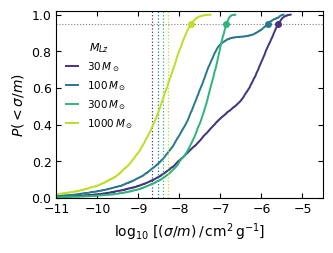

In [7]:
COLS = dict(zip(SCAN, plt.cm.viridis(np.linspace(0.15, 0.9, len(SCAN)))))
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 7.5, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.6))
    for m in SCAN:
        x = np.sort(np.log10(SIG[m]))
        ax.step(x, np.arange(1, len(x) + 1) / len(x), where='post', color=COLS[m], lw=1.4,
                label=rf'${m:g}\,M_\odot$')
        ax.plot([np.log10(np.percentile(SIG[m], 95))], [0.95], 'o', color=COLS[m], ms=4, zorder=5)
        ax.axvline(np.log10(INJ[m]), color=COLS[m], lw=0.9, ls=':')
    ax.axhline(0.95, color='0.5', ls=':', lw=0.8)
    ax.set(xlabel=r'$\log_{10}\,[(\sigma/m)\,/\,{\rm cm^2\,g^{-1}}]$', ylabel=r'$P(<\sigma/m)$',
           xlim=(-11, -4.5), ylim=(0, 1.02))
    ax.legend(frameon=False, loc='center left', bbox_to_anchor=(0.0, 0.6), title=r'$M_{Lz}$', title_fontsize=8,
              handlelength=1.2)
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'sidm_mass_scan.png', dpi=300, bbox_inches='tight')
    plt.show()

Cumulative posterior of $\sigma/m$ for each lens mass. Dots mark the 95% upper limits, and dotted vertical lines the injected values ($x_c = 0.02$).

## 5. Comparison with other SIDM probes

The paper's comparison figure places these limits against published SIDM constraints, as a function of the mean relative velocity of the lens halo. For LIGO, where inference results exist, the figure shows only those. For reference, we also compute the LIGO Fisher forecast for a lens with a negligible core ($x_c = 0.002$, the smallest grid core) at $y = 0.3$: for each grid mass we draw from the Fisher Gaussian restricted to the inference prior (Sec. 2), give each draw a $z_L$ from $P(z_L \mid M_{Lz})$, and take the 95th percentile of $\sigma/m$. It starts at $M_{Lz} = 100\,M_\odot$, the lightest informative inference run, interpolated in $\log M_{Lz}$. Triangles are the inference limits of Sec. 4 at $M_{Lz} = 100$, 300 and $1000\,M_\odot$ (lighter lenses are prior dominated). Each point sits at the median $\langle v\rangle$ of a lens of its mass.

In [8]:
LIT = [  # (label, v_lo, v_hi [km/s], value or (lo, hi) [cm^2/g], kind, colour)
    ('Bullet Cluster', 3500, 4500, 0.7, 'ul', 'tab:brown'),
    ('cluster mergers', 500, 4000, 2.0, 'soft', 'tab:olive'),
    ('cluster halo shapes', 1100, 1500, 1.0, 'soft', 'tab:pink'),
    ('cluster strong lensing', 1300, 1620, 0.13, 'ul', 'tab:red'),
    ('relaxed clusters', 1700, 2100, 0.35, 'ul', 'darkred'),
    ('relaxed groups', 1000, 1300, 1.1, 'ul', 'tab:orange'),
    ('clusters', 1000, 2100, (0.06, 0.28), 'range', 'tab:red'),
    ('groups', 1000, 1300, (0.3, 0.7), 'range', 'tab:orange'),
    ('dwarf/LSB rotation curves', 30, 200, (1.5, 2.5), 'range', 'tab:green'),
    ('too-big-to-fail', 40, 60, (0.5, 50.0), 'range', 'tab:cyan'),
    ('MW dSphs, gravothermal', 20, 60, (20.0, 150.0), 'range', 'tab:purple'),
    ('strong-lens flux ratios', 3, 30, (100.0, 1000.0), 'cond', 'tab:gray'),
]
CITE = {'Bullet Cluster': 'Randall+08', 'cluster mergers': 'Harvey+15, Wittman+18', 'cluster halo shapes': 'Peter+13',
        'cluster strong lensing': 'Andrade+22', 'relaxed clusters': 'Sagunski+21', 'relaxed groups': 'Sagunski+21',
        'clusters': 'Kaplinghat+16, Sagunski+21', 'groups': 'Sagunski+21', 'dwarf/LSB rotation curves': 'Kaplinghat+16',
        'too-big-to-fail': 'Zavala+13, Elbert+15', 'MW dSphs, gravothermal': 'Correa 21',
        'strong-lens flux ratios': 'Gilman+23'}

i0 = 0                                                    # smallest grid core, x_c = 0.002
fis = []
for j, M in enumerate(M_grid):
    if M < 70:
        continue
    w, V = np.linalg.eigh(grid['cov_t'][i0, j, k])
    d = np.array((np.log(M), Y_TRUE, grid['x_c'][i0])) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
    d = d[(d[:, 0] >= LNM_BOX[0]) & (d[:, 0] <= LNM_BOX[1]) & (d[:, 1] >= Y_BOX[0]) & (d[:, 1] <= Y_BOX[1])
          & (d[:, 2] >= XC_BOX[0]) & (d[:, 2] <= XC_BOX[1])][:60000]
    mlz = np.exp(d[:, 0])
    s_m = v_and_sigma_over_m(np.maximum(d[:, 2], 1e-8), mlz, draw_zL(mlz))[1]
    v_m = v_and_sigma_over_m(0.0, float(M), draw_zL(np.full(20000, float(M))))[0]
    fis.append((M, np.median(v_m), np.percentile(s_m, 95)))
fis = np.array(fis)
lm = np.log10(fis[:, 0])
start = [100.0, 10 ** np.interp(2.0, lm, np.log10(fis[:, 1])), 10 ** np.interp(2.0, lm, np.log10(fis[:, 2]))]
fis = np.vstack([start, fis[fis[:, 0] > 100]])
pd.DataFrame(fis, columns=['M_Lz', '<v> [km/s]', 'Fisher sigma/m 95% UL [cm2/g]']).style.format('{:.3g}')

,M_Lz,[km/s],Fisher sigma/m 95% UL [cm2/g]
0,100,3.96,2.76e-06
1,132,4.25,2.57e-06
2,228,4.87,2.24e-06
3,392,5.58,6.99e-08
4,675,6.39,1.95e-08
5,1.16e+03,7.32,1.39e-08
6,2e+03,8.38,3.51e-09


### LISA forecasts

The same Fisher forecast for the two LISA sources of the core-size grids, equal-mass binaries of $10^4+10^4$ and $10^6+10^6\,M_\odot$ at $z_S = 3$ observed for the last month before merger, at their native SNR (26 and 56), with $y = 0.3$ and a negligible core ($x_c = 0.002$). There is no inference prior to restrict to, so the Fisher Gaussian is restricted to physical values, $0 \le x_c \le 1$ and $0.1 \le y \le 5$, and the lens redshift is marginalized with T23's distribution for $z_S = 3$, where the mass function now matters. Each line is shown where the 95% upper limit on $x_c$ is below 0.5, the criterion used for the inference runs, and stops where the band would need FIONA above $w = 254$. The grids ship in `data/core_fisher_LISA_mbbh{1e4,1e6}_CIS.npz` (`scripts/1_fisher/core_size_fisher.py LISA [--m-bbh 1e4]`).

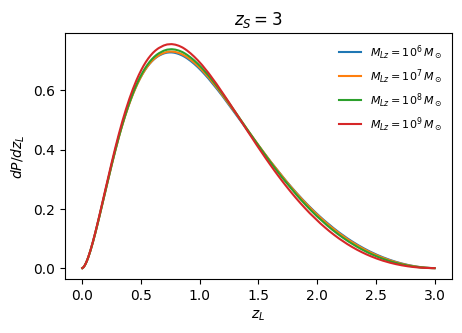

,M_Lz,x_c 95% UL,[km/s],sigma/m 95% UL [cm2/g]
0,2.15e+06,0.452,24.8,0.000732
1,4.64e+06,0.131,30,6.15e-05
2,1e+07,0.0622,36.4,1.63e-05
3,2.15e+07,0.0377,44.1,7.14e-06


,M_Lz,x_c 95% UL,[km/s],sigma/m 95% UL [cm2/g]
0,2.15e+08,0.053,78.3,2.53e-05
1,4.64e+08,0.0233,94.9,5.95e-06
2,1e+09,0.0153,115,3.06e-06


In [9]:
ZLISA = LensRedshift(3.0, 2.5, 9.6)
fig, ax = plt.subplots(figsize=(5, 3.2))
for m in [1e6, 1e7, 1e8, 1e9]:
    ax.plot(ZLISA.z, ZLISA.pdf(m), label=rf'$M_{{Lz}}=10^{{{int(np.log10(m))}}}\,M_\odot$')
ax.set(xlabel='$z_L$', ylabel=r'$dP/dz_L$', title='$z_S = 3$')
ax.legend(fontsize=8, frameon=False)
plt.show()

LISA = {}
for tag, label in [('LISA_mbbh1e4', r'$10^4+10^4\,M_\odot$'), ('LISA_mbbh1e6', r'$10^6+10^6\,M_\odot$')]:
    fn = paths.DATA_DIR / f'core_fisher_{tag}_CIS.npz'
    if not fn.exists():
        continue
    g = np.load(fn)
    kk = list(g['y']).index(Y_TRUE)
    rows = []
    for j, M in enumerate(g['M_Lz']):
        cov = g['cov_t'][0, j, kk]
        if not np.all(np.isfinite(cov)):
            continue                                       # band would need FIONA above w = 254
        w, V = np.linalg.eigh(cov)
        d = np.array((np.log(M), Y_TRUE, g['x_c'][0])) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
        d = d[(d[:, 1] >= Y_BOX[0]) & (d[:, 1] <= Y_BOX[1]) & (d[:, 2] >= XC_BOX[0]) & (d[:, 2] <= XC_BOX[1])][:60000]
        if len(d) < 1000 or np.percentile(d[:, 2], 95) >= 0.5:
            continue                                       # x_c not constrained
        mlz = np.exp(d[:, 0])
        s_m = ZLISA.v_and_sigma_over_m(np.maximum(d[:, 2], 1e-8), mlz, ZLISA.draw(mlz))[1]
        v_m = ZLISA.v_and_sigma_over_m(0.0, float(M), ZLISA.draw(np.full(20000, float(M))))[0]
        rows.append((M, np.percentile(d[:, 2], 95), np.median(v_m), np.percentile(s_m, 95)))
    LISA[tag] = (label, np.array(rows), float(g['snr_unlensed']))
    display(pd.DataFrame(rows, columns=['M_Lz', 'x_c 95% UL', '<v> [km/s]', 'sigma/m 95% UL [cm2/g]'])
            .style.format('{:.3g}').set_caption(f'LISA {label}, SNR {float(g["snr_unlensed"]):.0f}'))

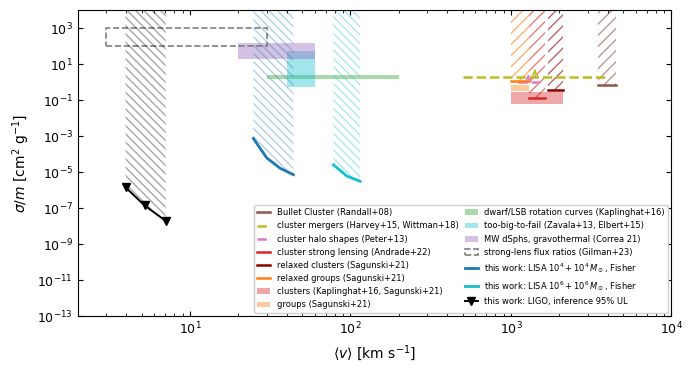

In [10]:
TOP = 1e4
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(7.0, 3.8))
    handles, labels = [], []
    for lab, v0, v1, val, kind, col in LIT:
        if kind in ('ul', 'soft'):          # upper limit (hatched above) or model-dependent limit (dashed)
            ls = '-' if kind == 'ul' else '--'
            ax.plot([v0, v1], [val, val], color=col, lw=1.8, ls=ls)
            if kind == 'ul':
                ax.add_patch(plt.Rectangle((v0, val), v1 - v0, TOP - val, facecolor='none', edgecolor=col, hatch='///',
                                           lw=0, alpha=0.6))
            else:
                ax.annotate('', xy=(np.sqrt(v0 * v1), val * 4), xytext=(np.sqrt(v0 * v1), val),
                            arrowprops=dict(arrowstyle='->', color=col, lw=1.2, ls='--'))
            handles.append(plt.Line2D([], [], color=col, lw=1.8, ls=ls))
        else:                               # measured or preferred range (filled), or conditional (dashed box)
            filled = kind == 'range'
            ax.add_patch(plt.Rectangle((v0, val[0]), v1 - v0, val[1] - val[0], facecolor=col if filled else 'none',
                                       edgecolor='none' if filled else col, alpha=0.4 if filled else 1, ls='--', lw=1.2))
            handles.append(plt.Rectangle((0, 0), 1, 1, facecolor=col if filled else 'none',
                                         edgecolor='none' if filled else col, alpha=0.4 if filled else 1, ls='--', lw=1.2))
        labels.append(f'{lab} ({CITE[lab]})')
    for (lab_l, arr, snr), col in zip(LISA.values(), ['tab:blue', 'tab:cyan']):
        ax.plot(arr[:, 2], arr[:, 3], '-', color=col, lw=2)
        ax.fill_between(arr[:, 2], arr[:, 3], TOP, facecolor='none', edgecolor=col, hatch='\\\\\\\\', lw=0, alpha=0.35)
        handles.append(plt.Line2D([], [], color=col, lw=2)); labels.append(f'this work: LISA {lab_l}, Fisher')
    pe = np.array([(VEL[m], np.percentile(SIG[m], 95)) for m in [100, 300, 1000]])
    ax.plot(pe[:, 0], pe[:, 1], 'v-', color='k', ms=6, lw=1.4)
    ax.fill_between(pe[:, 0], pe[:, 1], TOP, facecolor='none', edgecolor='k', hatch='\\\\\\\\', lw=0, alpha=0.35)
    handles.append(plt.Line2D([], [], marker='v', color='k', ls='-', lw=1.4, ms=6))
    labels.append('this work: LIGO, inference 95% UL')
    ax.set(xscale='log', yscale='log', xlim=(2, 1e4), ylim=(1e-13, TOP),
           xlabel=r'$\langle v\rangle$ [km s$^{-1}$]', ylabel=r'$\sigma/m$ [cm$^2$ g$^{-1}$]')
    ax.legend(handles, labels, fontsize=6, loc='lower right', bbox_to_anchor=(1.0, 0.0), ncol=2, frameon=True,
              framealpha=0.95, edgecolor='0.8', handlelength=1.5, columnspacing=0.8, borderaxespad=0.4)
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'sidm_probes.png', dpi=300, bbox_inches='tight')
    plt.show()

Hatched: excluded. Filled: measured or preferred. Dashed: model dependent. Comparing across velocities assumes a velocity-independent cross section.

## 6. Ultralight-axion mass from the CIS core

Following T23 (their Sec. VI.B), we read the CIS core as the soliton of an ultralight-axion halo. The soliton has a minimum half-density radius $r_{1/2} \ge 0.33\,{\rm kpc}\,(10^9\,M_\odot/M_c)(10^{-22}\,{\rm eV}/m_a)^2$, its mass follows from the virial mass, $M_c = 6.7\times10^7\,M_\odot\,(1+z_L)^{1/2}(M_{\rm vir}/10^{10}\,M_\odot)^{1/3}(m_a/10^{-22}\,{\rm eV})^{-1}$, and with $x_c \simeq r_{1/2}/\xi_0$ and T23's SIS relation for $M_{\rm vir}(M_{Lz}, z_L)$ (their Eq. A11),
$$x_c \ge \frac{50.4}{(1+z_L)^{3/2}}\,\frac{10^{10}\,M_\odot}{M_{\rm vir}}\,\frac{10^{-22}\,{\rm eV}}{m_a}\,\frac{1\,{\rm Gpc}}{d_{\rm eff}}\qquad\text{(T23 Eq. 76)}.$$
We checked the prefactor by rederiving it (50.5). A lens with a small core therefore sets a lower limit on $m_a$: for each posterior sample (or Fisher draw) of $(M_{Lz}, x_c)$, with $z_L$ drawn from T23's distribution as in Sec. 4, $m_a = 50.4\times10^{-22}\,{\rm eV}/[(1+z_L)^{3/2}(M_{\rm vir}/10^{10}\,M_\odot)(d_{\rm eff}/{\rm Gpc})\,x_c]$, and the 5th percentile of $m_a$ is the 95% lower limit. Each limit is placed at the median virial mass of a lens of its $M_{Lz}$.

In [11]:
def ma_from_xc(xc, mlz, zl, zsampler):
    # T23 Eq. (76): the axion mass for which the minimum soliton core equals x_c [eV]
    deff = np.interp(zl, zsampler.z, zsampler.deff)
    mv = m_vir(mlz, zl, deff)
    return 50.4e-22 / ((1 + zl) ** 1.5 * (mv / 1e10) * deff * np.asarray(xc))


def median_mvir(M, zsampler):
    zl = zsampler.draw(np.full(20000, float(M)))
    return np.median(m_vir(float(M), zl, np.interp(zl, zsampler.z, zsampler.deff)))


# LIGO: inference along the CIS mass scan (informative runs, M_Lz >= 100)
ULA_PE = []
for m in [100, 300, 1000]:
    s, _ = posteriors.load_fiona(posteriors.fiona_label('CIS', Y_TRUE, XC_TRUE, mlz=m))
    mlz = np.asarray(s['MLz'])
    ma = ma_from_xc(np.maximum(s['lp'], 1e-8), mlz, ZLIGO.draw(mlz), ZLIGO)
    ULA_PE.append((m, median_mvir(m, ZLIGO), np.percentile(ma, 5)))
ULA_PE = np.array(ULA_PE)

# LISA: prior-truncated Fisher draws, as in Sec. 5
ULA_LISA = {}
for tag, label in [('LISA_mbbh1e4', r'$10^4+10^4\,M_\odot$'), ('LISA_mbbh1e6', r'$10^6+10^6\,M_\odot$')]:
    fn = paths.DATA_DIR / f'core_fisher_{tag}_CIS.npz'
    if not fn.exists():
        continue
    g = np.load(fn)
    kk = list(g['y']).index(Y_TRUE)
    rows = []
    for j, M in enumerate(g['M_Lz']):
        cov = g['cov_t'][0, j, kk]
        if not np.all(np.isfinite(cov)):
            continue
        w, V = np.linalg.eigh(cov)
        d = np.array((np.log(M), Y_TRUE, g['x_c'][0])) + Z @ (V * np.sqrt(np.clip(w, 0, None))).T
        d = d[(d[:, 1] >= Y_BOX[0]) & (d[:, 1] <= Y_BOX[1]) & (d[:, 2] >= XC_BOX[0]) & (d[:, 2] <= XC_BOX[1])][:60000]
        if len(d) < 1000 or np.percentile(d[:, 2], 95) >= 0.5:
            continue
        mlz = np.exp(d[:, 0])
        ma = ma_from_xc(np.maximum(d[:, 2], 1e-8), mlz, ZLISA.draw(mlz), ZLISA)
        rows.append((M, median_mvir(M, ZLISA), np.percentile(ma, 5)))
    ULA_LISA[tag] = (label, np.array(rows))

rows = [dict(source='LIGO inference', M_Lz=r[0], M_vir=r[1], m_a_95_lower=r[2]) for r in ULA_PE]
for tag, (label, arr) in ULA_LISA.items():
    rows += [dict(source=f'LISA {tag[-3:]} Fisher', M_Lz=r[0], M_vir=r[1], m_a_95_lower=r[2]) for r in arr]
pd.DataFrame(rows).style.format({'M_Lz': '{:.3g}', 'M_vir': '{:.3g}', 'm_a_95_lower': '{:.3g}'}).hide(axis='index')

source,M_Lz,M_vir,m_a_95_lower
LIGO inference,100,2.94e+06,2.61e-16
LIGO inference,300,6.69e+06,4.99e-16
LIGO inference,1e+03,1.65e+07,7.59e-16
LISA 1e4 Fisher,2.15e+06,7.2e+08,6.88e-20
LISA 1e4 Fisher,4.64e+06,1.28e+09,2.29e-19
LISA 1e4 Fisher,1e+07,2.27e+09,3.06e-19
LISA 1e4 Fisher,2.15e+07,4.04e+09,2.94e-19
LISA 1e6 Fisher,2.15e+08,2.27e+10,3.84e-20
LISA 1e6 Fisher,4.64e+08,4.03e+10,4.81e-20
LISA 1e6 Fisher,1e+09,7.15e+10,4.2e-20


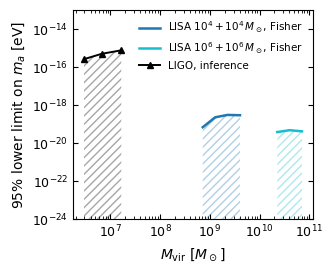

In [12]:
BOTTOM = 1e-24
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'legend.fontsize': 7.5, 'xtick.direction': 'in',
                     'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.8))
    for (label, arr), col in zip(ULA_LISA.values(), ['tab:blue', 'tab:cyan']):
        ax.plot(arr[:, 1], arr[:, 2], '-', color=col, lw=1.8, label=f'LISA {label}, Fisher')
        ax.fill_between(arr[:, 1], BOTTOM, arr[:, 2], facecolor='none', edgecolor=col, hatch='////', lw=0, alpha=0.35)
    ax.plot(ULA_PE[:, 1], ULA_PE[:, 2], '^-', color='k', ms=5, lw=1.4, label='LIGO, inference')
    ax.fill_between(ULA_PE[:, 1], BOTTOM, ULA_PE[:, 2], facecolor='none', edgecolor='k', hatch='////', lw=0, alpha=0.35)
    ax.set(xscale='log', yscale='log', ylim=(BOTTOM, 1e-13), xlabel=r'$M_{\rm vir}\ [M_\odot]$',
           ylabel=r'95% lower limit on $m_a$ [eV]')
    ax.legend(frameon=False, loc='upper right')
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'ula_ma_limits.png', dpi=300, bbox_inches='tight')
    plt.show()

Lower limits on the axion mass from a lens with a small core, against the virial mass of the lens halo, with the excluded region below each curve hatched. The CIS-core interpretation follows T23, and T23 caution that it describes low-mass ULA halos, which flatten into a CIS-like core, better than heavier halos with a steep soliton.

## 7. Comparison with other ultralight-axion bounds

The limits of Sec. 6 against the most competitive bounds on the axion mass. Bounds from structure assume that the axion makes up all of the dark matter and exclude masses below a value: the Lyman-$\alpha$ forest ($m_a > 2\times10^{-20}$ eV, Rogers & Peiris 2021), Milky Way satellites ($m_a > 2.9\times10^{-21}$ eV, Nadler et al. 2021), stellar heating in ultra-faint dwarfs ($m_a > 3\times10^{-19}$ eV, Dalal & Kravtsov 2022), and the CMB and galaxy clustering ($10^{-32} < m_a < 10^{-25.5}$ eV excluded, Hlozek et al. 2015). Black-hole superradiance excludes windows of $m_a$ independently of the axion abundance (spins of stellar-mass and supermassive black holes without axion self-interactions, Stott 2020, from the AxionLimits compilation of O'Hare). These bounds do not depend on the halo mass and are drawn across the full width of the figure.

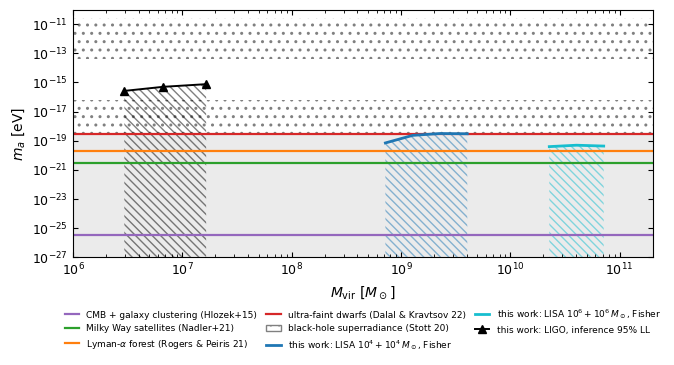

In [13]:
EXT = paths.DATA_DIR / 'external_bounds'
ULA_LIT = [  # (label, lower limit on m_a [eV], colour): m_a below the value is excluded
    ('CMB + galaxy clustering (Hlozek+15)', 10 ** -25.5, 'tab:purple'),
    ('Milky Way satellites (Nadler+21)', 2.9e-21, 'tab:green'),
    (r'Lyman-$\alpha$ forest (Rogers & Peiris 21)', 2e-20, 'tab:orange'),
    ('ultra-faint dwarfs (Dalal & Kravtsov 22)', 3e-19, 'tab:red'),
]
sr = np.loadtxt(EXT / 'AxionLimits' / 'BlackHoleSpins_noSI.txt')
SR_WINDOWS = [(sr[i, 0], sr[i + 2, 0]) for i in range(0, len(sr), 4)]     # excluded [m_lo, m_hi] windows

XLIM, YLIM = (1e6, 2e11), (1e-27, 1e-10)
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(7.0, 3.8))
    handles, labels = [], []
    ax.axhspan(YLIM[0], max(m for _, m, _ in ULA_LIT), color='0.85', alpha=0.5, lw=0, zorder=0)   # excluded by structure
    for lab, m, col in ULA_LIT:
        ax.axhline(m, color=col, lw=1.6)
        handles.append(plt.Line2D([], [], color=col, lw=1.6)); labels.append(lab)
    for k_, (lo, hi) in enumerate(SR_WINDOWS):
        ax.axhspan(lo, hi, facecolor='none', edgecolor='0.5', hatch='..', lw=0)
    handles.append(plt.Rectangle((0, 0), 1, 1, facecolor='none', edgecolor='0.5', hatch='..')); labels.append('black-hole superradiance (Stott 20)')
    for (label, arr), col in zip(ULA_LISA.values(), ['tab:blue', 'tab:cyan']):
        ax.plot(arr[:, 1], arr[:, 2], '-', color=col, lw=2)
        ax.fill_between(arr[:, 1], YLIM[0], arr[:, 2], facecolor='none', edgecolor=col, hatch='\\\\\\\\', lw=0, alpha=0.5)
        handles.append(plt.Line2D([], [], color=col, lw=2)); labels.append(f'this work: LISA {label}, Fisher')
    ax.plot(ULA_PE[:, 1], ULA_PE[:, 2], '^-', color='k', ms=6, lw=1.4)
    ax.fill_between(ULA_PE[:, 1], YLIM[0], ULA_PE[:, 2], facecolor='none', edgecolor='k', hatch='\\\\\\\\', lw=0, alpha=0.5)
    handles.append(plt.Line2D([], [], marker='^', color='k', lw=1.4, ms=6)); labels.append('this work: LIGO, inference 95% LL')
    ax.set(xscale='log', yscale='log', xlim=XLIM, ylim=YLIM, xlabel=r'$M_{\rm vir}\ [M_\odot]$', ylabel=r'$m_a$ [eV]')
    ax.legend(handles, labels, fontsize=6.5, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=3, frameon=False,
              handlelength=1.6, columnspacing=1.0)
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'ula_probes.png', dpi=300, bbox_inches='tight')
    plt.show()

The lensing limits are lower limits on $m_a$ for the dark matter in the lens halo, conditional on the CIS-core reading of Sec. 6. The structure bounds assume the axion is all of the dark matter and constrain the population of halos.

## 8. Primordial black holes

For a point lens the lens mass is the black-hole mass, $M_{\rm PBH} = M_{Lz}/(1+z_L)$. A single lensed event measures that mass, but it does not constrain the PBH abundance, which would require the rate of lensed events. The figure therefore places the measured masses of the PBH mass scan (2$\sigma$ intervals, $z_L$ marginalized as in Sec. 4) on the standard plot of bounds on the PBH dark-matter fraction $f_{\rm PBH}$, from the PBHbounds compilation (Kavanagh): envelopes of the microlensing, accretion, and dynamical bounds, the LIGO merger-rate bound, and the projected bound from the non-observation of GW lensing (dashed).

M_Lz,M_PBH 2sigma lo,median,M_PBH 2sigma hi,injected M_PBH (median z_L)
30,14.3,25.1,40.7,28.5
100,39,66.5,121,95
300,278,426,766,285
1e+03,682,841,1.1e+03,950


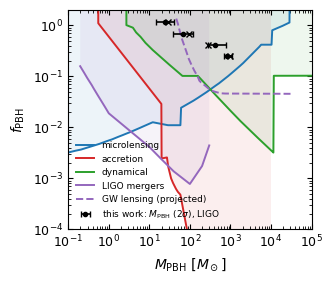

In [14]:
PBH_M = []
for m in [30, 100, 300, 1000]:
    s, _ = posteriors.load_fiona(posteriors.fiona_label('PBH', Y_TRUE, None, mlz=m))
    mlz = np.asarray(s['MLz'])
    mp = mlz / (1 + ZLIGO.draw(mlz))
    PBH_M.append((m, *np.percentile(mp, [2.275, 50, 97.725]), np.median(m / (1 + ZLIGO.draw(np.full(20000, float(m)))))))
PBH_M = np.array(PBH_M)
display(pd.DataFrame(PBH_M, columns=['M_Lz', 'M_PBH 2sigma lo', 'median', 'M_PBH 2sigma hi', 'injected M_PBH (median z_L)'])
        .style.format('{:.3g}').hide(axis='index'))

PBH_LIT = [('Microlensing', 'microlensing', 'tab:blue', '-'), ('Accretion', 'accretion', 'tab:red', '-'),
           ('Dynamical', 'dynamical', 'tab:green', '-'), ('LIGO', 'LIGO mergers', 'tab:purple', '-'),
           ('GW-Lensing', 'GW lensing (projected)', 'tab:purple', '--')]
with plt.rc_context({'font.size': 9, 'axes.labelsize': 10, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.top': True, 'ytick.right': True}):
    fig, ax = plt.subplots(figsize=(3.4, 2.9))
    for fn, lab, col, ls in PBH_LIT:
        b = np.loadtxt(EXT / 'PBHbounds' / f'{fn}.txt')
        ax.plot(b[:, 0], b[:, 1], ls, color=col, lw=1.4, label=lab)
        if ls == '-':
            ax.fill_between(b[:, 0], b[:, 1], 1e3, color=col, alpha=0.08, lw=0)
    for k_, (m, lo, med, hi, inj) in enumerate(PBH_M):
        yb = 1.15 * 0.6 ** k_                       # stagger the four runs vertically
        ax.errorbar([med], [yb], xerr=[[med - lo], [hi - med]], fmt='o', color='k', ms=3, capsize=2, lw=1.2,
                    label=r'this work: $M_{\rm PBH}$ (2$\sigma$), LIGO' if k_ == 0 else None)
        ax.plot([inj], [yb], 'x', color='k', ms=4)
    ax.set(xscale='log', yscale='log', xlim=(1e-1, 1e5), ylim=(1e-4, 2), xlabel=r'$M_{\rm PBH}\ [M_\odot]$', ylabel=r'$f_{\rm PBH}$')
    ax.legend(fontsize=6.5, frameon=False, loc='lower left')
    fig.tight_layout()
    fig.savefig(paths.FIGURES_DIR / 'pbh_probes.png', dpi=300, bbox_inches='tight')
    plt.show()

Black bars: the medians and $2\sigma$ intervals of $M_{\rm PBH}$ from the PBH mass scan ($M_{Lz} = 30$, 100, 300, $1000\,M_\odot$, top to bottom), with the injected masses as crosses. Their vertical position has no meaning. Shaded regions above the solid curves are excluded if PBHs of a single mass make up the fraction $f_{\rm PBH}$ of the dark matter.